Chapter 1 found that returns are almost uncorrelated but their *size* is strongly autocorrelated: volatility clusters. Chapter 2 relied on that, scaling every position by an estimate of its volatility. This chapter takes volatility forecasting seriously. It is the most successful forecasting problem in finance, and the base of risk management, option pricing (Chapter 8) and position sizing.

:::eli5
Weather forecasters cannot tell you exactly where lightning will strike tomorrow, but they can tell you a storm is likely, because storms last for days. Markets are the same: nobody knows whether the market will go up or down tomorrow, but after a few wild days it is very likely that tomorrow will be wild too. Forecasting volatility is forecasting the storm, not the lightning.
:::

## Look at the big picture

**The problem.** Each day, forecast the volatility of SPY over the next month (21 trading days), as an annualised number. **Why it matters:** a risk manager sets position limits with it, an options trader compares it with the volatility implied by option prices, and a portfolio manager scales exposure with it. **The users** need a forecast that is accurate on average, reacts quickly to regime changes and is never absurd.

**Performance measure.** Volatility is never observed directly, only noisy proxies of it, so the choice of loss matters. We use the **QLIKE** loss, which Patton (2011) proved ranks forecasts correctly even when the target is a noisy proxy, plus the mean squared error of variance for comparison, and a regression check of bias.

## Get the data

SPY daily open, high, low and close since 1993 (Yahoo Finance, adjusted), and the VIX index since 1993 (FRED).

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import stats, optimize, signal
import json, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

spy = pd.read_csv(DATA / "spy_ohlc.csv", index_col="date", parse_dates=True)
vix = pd.read_csv(DATA / "vix.csv", index_col="date", parse_dates=True)["VIXCLS"]
bad = (spy.high < spy[["open", "close"]].max(axis=1)) | (spy.low > spy[["open", "close"]].min(axis=1))
print(spy.shape, spy.index[0].date(), "→", spy.index[-1].date(), "| inconsistent OHLC rows:", int(bad.sum()))
spy.tail(3)

(8497, 5) 1993-01-29 → 2026-10-30 | inconsistent OHLC rows: 0


,open,high,low,close,volume
date,,,,,
2026-10-28,771.43,773.36,769.24,772.31,30133800
2026-10-29,768.79,770.76,766.62,769.36,40299600
2026-10-30,761.38,761.46,750.36,755.72,77696500


## Measuring volatility from prices

The textbook measure of a day's variance is its squared return $r_t^2$. It is unbiased but extremely noisy: a day can end where it started after a huge swing in between. The **high** and **low** of the day contain much more information.

:::math
With open $O$, high $H$, low $L$ and close $C$:

- **Close-to-close:** $\hat\sigma^2_{\text{cc}} = r_t^2$ with $r_t = \ln(C_t / C_{t-1})$.
- **Parkinson (1980):** $\hat\sigma^2_{\text{P}} = \dfrac{(\ln H_t / L_t)^2}{4 \ln 2}$. For a random walk the expected squared range is $4 \ln 2$ times the variance.
- **Garman–Klass (1980):** $\hat\sigma^2_{\text{GK}} = \tfrac12 (\ln H_t/L_t)^2 - (2\ln 2 - 1)(\ln C_t/O_t)^2$, about seven times more efficient than close-to-close for a random walk.

Ranges only cover the trading session, so we add the overnight gap $(\ln O_t / C_{t-1})^2$ to get a full-day measure.
:::

In [2]:
r = np.log(spy.close).diff()
overnight = np.log(spy.open / spy.close.shift(1)) ** 2
park = np.log(spy.high / spy.low) ** 2 / (4 * np.log(2))
gk = 0.5 * np.log(spy.high / spy.low) ** 2 - (2 * np.log(2) - 1) * np.log(spy.close / spy.open) ** 2
rv_d = (overnight + gk).clip(lower=1e-10)                 # full-day range-based variance
df = pd.DataFrame({"r": r, "r2": r**2, "rv_d": rv_d, "park": park + overnight, "vix": vix.reindex(spy.index).ffill()}).dropna()

ann = lambda v: np.sqrt(v * 252)
print("average annualised vol: close-to-close %.1f%%, Parkinson %.1f%%, GK+overnight %.1f%%" %
      tuple(100 * ann(df[c].mean()) for c in ["r2", "park", "rv_d"]))
# noise: how well does each daily measure predict the next 21 days' squared returns?
fut = df["r2"][::-1].rolling(21).sum()[::-1].shift(-1)
for c in ["r2", "park", "rv_d"]:
    print(f"corr of {c:5s} (21-day avg) with next-month variance: {df[c].rolling(21).mean().corr(fut):.3f}")

average annualised vol: close-to-close 18.5%, Parkinson 18.7%, GK+overnight 18.8%
corr of r2    (21-day avg) with next-month variance: 0.532
corr of park  (21-day avg) with next-month variance: 0.547
corr of rv_d  (21-day avg) with next-month variance: 0.542


Averaged over many days the three measures agree on the level of volatility, but the range-based ones are much less noisy, so their recent average predicts next month's variance better. From now on `rv_d` (Garman–Klass plus overnight) is our daily realised-variance measure for *inputs*, while forecasts are scored against what an investor experiences: the sum of squared close-to-close returns over the next 21 days.

### The target

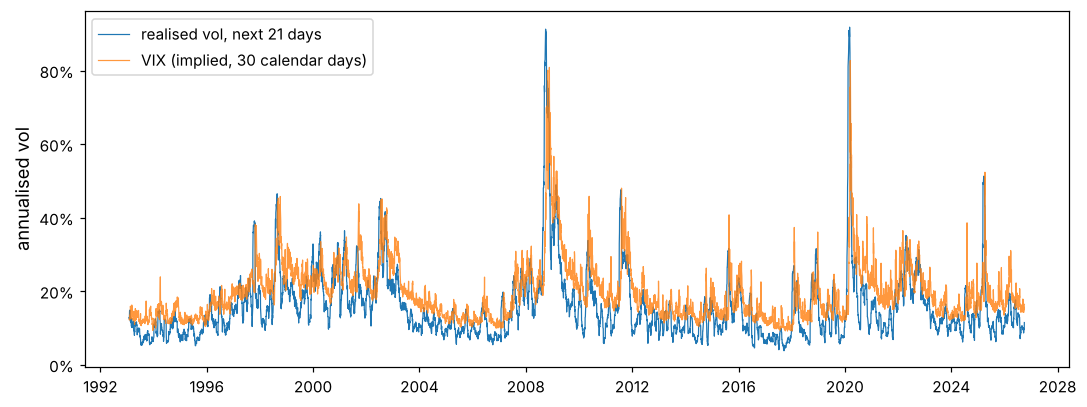

In [3]:
H = 21
df["target"] = df["r2"][::-1].rolling(H).sum()[::-1].shift(-1)          # sum of r^2 over t+1 ... t+21
df = df.dropna(subset=["target"])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ann(df["target"] / H), lw=0.8, label="realised vol, next 21 days")
ax.plot(df["vix"] / 100, lw=0.8, alpha=0.8, label="VIX (implied, 30 calendar days)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(); ax.set_ylabel("annualised vol")
save_fig("target_vix"); plt.show()
vrp = (df["vix"] / 100) ** 2 - df["target"] / H * 252
R["vrp_share"] = f"{(vrp > 0).mean():.0%}"
R["vix_mean"] = f"{df['vix'].mean():.1f}"; R["rv_mean"] = f"{100 * ann(df['target'].mean() / H):.1f}"

![Figure 3-1. The forecasting target (volatility realised over the next 21 trading days) and the VIX, the market's own forecast derived from option prices.](images/target_vix.png)

The VIX averaged 19.5% while realised volatility averaged 18.5%, and implied variance exceeded the variance that followed on 84% of days. This gap is the **volatility risk premium**: investors pay up for options because options insure against crashes. It means the VIX is a *biased* forecast, too high on average, although it may still carry useful information. Selling that insurance is a strategy in itself (Chapter 8).

## The models

### 1. Historical volatility and EWMA

The simplest forecasts: the average squared return over a past window, and the **exponentially weighted moving average** (EWMA) used by RiskMetrics,

$$\hat\sigma^2_{t+1} = \lambda\,\hat\sigma^2_t + (1 - \lambda)\, r_t^2, \qquad \lambda = 0.94,$$

which gives weight $(1 - \lambda)\lambda^k$ to the return $k$ days ago (a half-life of about 11 days). Both forecast that volatility stays where it is: the forecast for every future day equals today's estimate.

In [4]:
df["f_hist21"] = df["r2"].rolling(21).mean() * H
df["f_hist252"] = df["r2"].rolling(252).mean() * H
lam = 0.94
ew = signal.lfilter([1 - lam], [1, -lam], df["r2"].to_numpy(), zi=[lam * df["r2"].iloc[:21].mean()])[0]
df["f_ewma"] = ew * H                                          # uses r^2 up to and including today

### 2. GARCH(1,1), from scratch

EWMA never reverts: after a crisis it predicts high volatility forever. Engle (1982) and Bollerslev (1986) proposed a model in which volatility is pulled back towards a long-run level.

:::math
**GARCH(1,1):** returns are $r_t = \mu + \sigma_t z_t$ with $z_t$ independent, mean 0 and variance 1, and the conditional variance follows

$$\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2, \qquad \varepsilon_t = r_t - \mu, \qquad \omega > 0,\ \alpha, \beta \geq 0,\ \alpha + \beta < 1.$$

$\alpha$ is how strongly volatility reacts to a shock, $\beta$ how long it remembers, and $\alpha + \beta$ is the **persistence**. The long-run variance is $\bar\sigma^2 = \omega / (1 - \alpha - \beta)$, and the $k$-step forecast decays geometrically towards it:

$$E_t[\sigma^2_{t+k}] = \bar\sigma^2 + (\alpha + \beta)^{k-1}\big(\sigma^2_{t+1} - \bar\sigma^2\big),$$

so the forecast of the variance over the next $H$ days is the sum of these terms. A shock's effect halves after $\ln 0.5 / \ln(\alpha + \beta)$ days.

**Estimation by maximum likelihood.** With normal $z_t$, the log-likelihood is $\ell = -\tfrac12\sum_t \big(\ln 2\pi + \ln\sigma_t^2 + \varepsilon_t^2 / \sigma_t^2\big)$, which we maximise numerically. With Student-t $z_t$ (scaled to unit variance) we add one parameter $\nu$ for fat tails. EWMA is the special case $\omega = 0$, $\alpha + \beta = 1$.
:::

The variance recursion is a linear filter, so `scipy.signal.lfilter` runs it in compiled code: thousands of likelihood evaluations take a fraction of a second.

In [5]:
from scipy.special import gammaln

def garch_filter(eps, omega, alpha, beta, gamma=0.0, s0=None):
    """sigma2[t] for t = 0..n-1, using eps up to t-1. gamma > 0 gives GJR (asymmetric) GARCH."""
    s0 = np.var(eps) if s0 is None else s0
    shock = (alpha + gamma * (eps < 0)) * eps**2
    u = omega + np.r_[0.0, shock[:-1]]                         # u[t] = omega + (alpha + gamma I) eps[t-1]^2
    u[0] = s0                                                  # so that sigma2[0] = s0
    return signal.lfilter([1.0], [1.0, -beta], u)              # sigma2[t] = u[t] + beta * sigma2[t-1]

def garch_nll(theta, x, dist="t", asym=False):
    """Negative log-likelihood. theta = (mu, omega, alpha, beta[, gamma][, nu]) for returns x."""
    mu, omega, alpha, beta = theta[:4]
    gamma = theta[4] if asym else 0.0
    eps = x - mu
    s2 = np.maximum(garch_filter(eps, omega, alpha, beta, gamma), 1e-12)
    if dist == "normal":
        return 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2) + eps**2 / s2)
    nu = theta[-1]                                             # Student-t scaled to unit variance
    ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2) * s2)
          - (nu + 1) / 2 * np.log1p(eps**2 / ((nu - 2) * s2)))
    return -np.sum(ll)

def fit_garch(r, dist="t", asym=False):
    x = np.asarray(r, float) * 100                             # percent returns: well-scaled for the optimiser
    v = x.var()
    x0 = [x.mean(), 0.05 * v, 0.05, 0.90] + ([0.05] if asym else []) + ([6.0] if dist == "t" else [])
    bounds = [(-1, 1), (1e-6, 10 * v), (0, 1), (0, 1)] + ([(0, 1)] if asym else []) + ([(2.1, 100)] if dist == "t" else [])
    stationary = {"type": "ineq", "fun": lambda th: 0.9999 - th[2] - th[3] - (th[4] / 2 if asym else 0.0)}
    res = optimize.minimize(garch_nll, x0, args=(x, dist, asym), method="SLSQP", bounds=bounds,
                            constraints=[stationary], options={"maxiter": 500, "ftol": 1e-10})
    th = res.x
    out = dict(mu=th[0] / 100, omega=th[1] / 1e4, alpha=th[2], beta=th[3], gamma=th[4] if asym else 0.0,
               nu=th[-1] if dist == "t" else np.inf, loglik=-res.fun - len(x) * np.log(100), ok=res.success)
    out["persistence"] = out["alpha"] + out["beta"] + out["gamma"] / 2
    return out

full = fit_garch(df["r"].to_numpy(), dist="t")
fullgjr = fit_garch(df["r"].to_numpy(), dist="t", asym=True)
for name, p in [("GARCH-t", full), ("GJR-GARCH-t", fullgjr)]:
    print(f"{name:12s} alpha={p['alpha']:.3f} beta={p['beta']:.3f} gamma={p['gamma']:.3f} nu={p['nu']:.1f} "
          f"persistence={p['persistence']:.4f} half-life={np.log(0.5)/np.log(p['persistence']):.0f} days "
          f"long-run vol={np.sqrt(p['omega']/(1-p['persistence'])*252):.1%} logL={p['loglik']:.0f}")
R["alpha"] = f"{full['alpha']:.3f}"; R["beta"] = f"{full['beta']:.3f}"; R["persist"] = f"{full['persistence']:.3f}"
R["halflife"] = f"{np.log(0.5)/np.log(full['persistence']):.0f}"; R["nu_g"] = f"{full['nu']:.1f}"
R["gjr_gamma"] = f"{fullgjr['gamma']:.3f}"; R["gjr_alpha"] = f"{fullgjr['alpha']:.3f}"
R["dll"] = f"{fullgjr['loglik'] - full['loglik']:.0f}"
try:                                                            # optional cross-check with the arch package
    from arch import arch_model
    chk = arch_model(df["r"] * 100, vol="GARCH", p=1, q=1, dist="t").fit(disp="off").params
    print("arch package:", {k: round(v, 4) for k, v in chk.items() if k in ["alpha[1]", "beta[1]", "nu"]})
except ImportError:
    print("(install the arch package to cross-check these estimates)")

GARCH-t      alpha=0.116 beta=0.879 gamma=0.000 nu=5.9 persistence=0.9956 half-life=156 days long-run vol=28.5% logL=-50255
GJR-GARCH-t  alpha=0.000 beta=0.885 gamma=0.198 nu=6.4 persistence=0.9835 half-life=42 days long-run vol=16.7% logL=-50127
arch package: {'alpha[1]': 0.1159, 'beta[1]': 0.8796, 'nu': 5.8627}


On the full sample, $\alpha = $ 0.116 and $\beta = $ 0.879: shocks enter slowly but are remembered for a long time. The persistence is 0.996, so a shock to volatility loses half its effect in about 156 days. Even after scaling by GARCH volatility the innovations need a Student-t with $\nu \approx$ 5.9: some fat-tailedness is left.

### 3. The leverage effect: GJR-GARCH

Chapter 1 found that falls raise volatility more than rises. The GJR model (Glosten, Jagannathan and Runkle, 1993) adds a term for negative shocks: $\sigma_t^2 = \omega + (\alpha + \gamma\,\mathbb 1[\varepsilon_{t-1} < 0])\,\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2$. Its estimate $\gamma = $ 0.198 against $\alpha = $ 0.000 means that, in SPY, essentially *all* of the reaction to news comes from bad news, and it improves the log-likelihood by 128 points for one extra parameter.

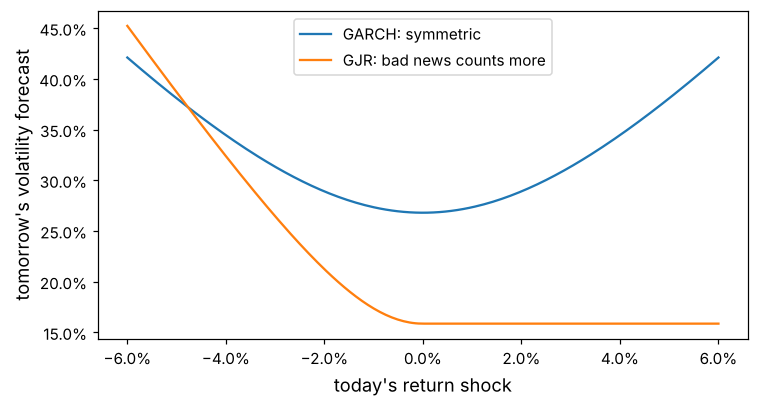

In [6]:
eps_grid = np.linspace(-0.06, 0.06, 200)
s_bar = full["omega"] / (1 - full["persistence"])
def nic(p, e):                                           # news impact curve: next variance after shock e
    s_bar_ = p["omega"] / (1 - p["persistence"])
    return p["omega"] + (p["alpha"] + p["gamma"] * (e < 0)) * e**2 + p["beta"] * s_bar_
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(eps_grid, ann(nic(full, eps_grid)), label="GARCH: symmetric")
ax.plot(eps_grid, ann(nic(fullgjr, eps_grid)), label="GJR: bad news counts more")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("today's return shock"); ax.set_ylabel("tomorrow's volatility forecast"); ax.legend()
save_fig("news_impact"); plt.show()

![Figure 3-2. The news impact curve: tomorrow’s volatility forecast as a function of today’s return, starting from the long-run level.](images/news_impact.png)

### 4. HAR: a linear model on realised volatility

Corsi (2009) noticed that traders operate at different horizons (daily, weekly, monthly) and proposed the **heterogeneous autoregressive** model: regress future realised variance on the averages of past realised variance over a day, a week and a month. Using logs keeps forecasts positive and the errors closer to normal:

$$\ln \text{RV}^{(21)}_{t+1} = b_0 + b_d \ln \text{RV}^{(1)}_t + b_w \ln \text{RV}^{(5)}_t + b_m \ln \text{RV}^{(21)}_t + b_v \ln \text{VIX}^2_t + e_t.$$

It is fitted by ordinary least squares, with no likelihood optimisation at all.

In [7]:
feat = pd.DataFrame({
    "rv1": np.log(df["rv_d"]),
    "rv5": np.log(df["rv_d"].rolling(5).mean()),
    "rv21": np.log(df["rv_d"].rolling(21).mean()),
    "rv63": np.log(df["rv_d"].rolling(63).mean()),
    "vix2": np.log((df["vix"] / 100) ** 2 / 252),
    "ret1": df["r"], "ret5": df["r"].rolling(5).sum(), "ret21": df["r"].rolling(21).sum(),
}, index=df.index)
feat["neg5"] = np.minimum(feat["ret5"], 0)                      # leverage effect in the HAR
y_log = np.log(df["target"] / H)                                 # log average daily variance ahead
print(feat.dropna().describe().T[["mean", "std"]].round(3))

        mean    std
rv1   -9.747  1.220
rv5   -9.536  1.032
rv21  -9.430  0.945
rv63  -9.342  0.885
vix2  -8.926  0.695
ret1   0.000  0.012
ret5   0.002  0.024
ret21  0.009  0.046
neg5  -0.007  0.016


### 5. Gradient boosting

Finally a machine-learning model: LightGBM gradient-boosted trees on the same features, predicting the log target. Trees can find non-linear interactions (for example, a high VIX matters more when realised volatility is low), but they cannot extrapolate beyond the range they have seen, an important weakness for volatility, whose extremes are what matter.

## Walk-forward evaluation

Every model is re-estimated at the start of each year from 2005 on, using **only data before that year** (an expanding window), and then forecasts each day of the year. This mimics how the forecasts would have been produced in real time. There is one more subtlety: the target over days $t+1 \dots t+21$ overlaps the next 20 targets, so the last 21 training observations before each refit are dropped to avoid any overlap with the test year (an **embargo**, which Chapter 5 formalises).

In [8]:
import lightgbm as lgb

years = range(2005, 2027)
cols = ["f_har", "f_garch", "f_gjr", "f_lgb", "f_vix_mz"]
for c in cols:
    df[c] = np.nan
har_cols = ["rv1", "rv5", "rv21", "vix2", "neg5"]
rr = df["r"].to_numpy()
garch_params = {}

def garch_month_forecast(p, s2_next):
    k = np.arange(H)
    s_bar_ = p["omega"] / (1 - p["persistence"])
    return np.sum(s_bar_ + p["persistence"] ** k * (s2_next - s_bar_))

for yr in years:
    test = df.index.year == yr
    if not test.any():
        continue
    first = np.argmax(test)
    train = np.arange(len(df)) < first - H                       # embargo: drop the last H days
    # GARCH and GJR: fit on the training returns, then filter through the whole sample
    for name, asym in [("f_garch", False), ("f_gjr", True)]:
        p = fit_garch(rr[train], dist="t", asym=asym)
        garch_params[(name, yr)] = p
        eps = rr - p["mu"]
        s2 = garch_filter(eps, p["omega"], p["alpha"], p["beta"], p["gamma"])
        s2_next = p["omega"] + (p["alpha"] + p["gamma"] * (eps < 0)) * eps**2 + p["beta"] * s2   # sigma^2 for t+1
        idx = np.where(test)[0]
        df.iloc[idx, df.columns.get_loc(name)] = [garch_month_forecast(p, s2_next[i]) for i in idx]
    # HAR (OLS on logs)
    X = feat[har_cols].assign(const=1.0); ok = X.notna().all(axis=1) & y_log.notna()
    tr = ok & train; te = ok & test
    beta_har, *_ = np.linalg.lstsq(X[tr].to_numpy(), y_log[tr].to_numpy(), rcond=None)
    resid_var = np.var(y_log[tr].to_numpy() - X[tr].to_numpy() @ beta_har)
    df.loc[te, "f_har"] = np.exp(X[te].to_numpy() @ beta_har + resid_var / 2) * H     # lognormal bias correction
    # VIX, recalibrated by a Mincer-Zarnowitz regression on past data
    vx = (df["vix"] / 100) ** 2 / 252 * H
    a_mz, b_mz = np.polyfit(vx[train & ok], df["target"][train & ok], 1)[::-1]
    df.loc[test, "f_vix_mz"] = (a_mz + b_mz * vx[test]).clip(lower=1e-6)
    # LightGBM on all features
    Xg = feat.dropna(); yg = y_log.reindex(Xg.index)
    trg = train[df.index.get_indexer(Xg.index)] & yg.notna().to_numpy()
    teg = test[df.index.get_indexer(Xg.index)]
    model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=50,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
    model.fit(Xg[trg], yg[trg])
    resid = yg[trg] - model.predict(Xg[trg])
    df.loc[Xg.index[teg], "f_lgb"] = np.exp(model.predict(Xg[teg]) + np.var(resid) / 2) * H

df["f_vix_raw"] = (df["vix"] / 100) ** 2 / 252 * H
ev = df.loc["2005":].dropna(subset=["target", "f_har", "f_garch", "f_gjr", "f_lgb", "f_vix_mz", "f_ewma", "f_hist21", "f_hist252"])
print(len(ev), "out-of-sample days from", ev.index[0].date(), "to", ev.index[-1].date())

5471 out-of-sample days from 2005-01-03 to 2026-10-01


### Loss functions that rank forecasts correctly

:::math
Let $h$ be the forecast of the variance and $\hat\sigma^2$ the realised proxy. Two losses:

$$\text{MSE} = (\hat\sigma^2 - h)^2, \qquad \text{QLIKE} = \frac{\hat\sigma^2}{h} - \ln\frac{\hat\sigma^2}{h} - 1.$$

MSE is dominated by a handful of crisis days and punishes large forecasts heavily. QLIKE is the loss implied by a normal likelihood; it penalises *under*-prediction of volatility more than over-prediction, which is what a risk manager wants, and Patton (2011) showed both are “robust”: with a noisy but unbiased proxy, they still rank forecasts as the true variance would.

To compare two models we use the **Diebold–Mariano** test: the mean loss difference $\bar d$ divided by its standard error. Because the targets overlap, the losses are autocorrelated and the standard error must be a heteroskedasticity-and-autocorrelation-consistent (Newey–West) one.
:::

In [9]:
def qlike(target, h):
    x = target / h
    return x - np.log(x) - 1

def newey_west_se(d, lags):
    d = np.asarray(d) - np.mean(d); n = len(d)
    s = np.sum(d * d) / n
    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * np.sum(d[k:] * d[:-k]) / n
    return np.sqrt(s / n)

def dm_test(loss_a, loss_b, lags=H):
    d = loss_a - loss_b
    t = d.mean() / newey_west_se(d, lags)
    return t, 2 * stats.norm.sf(abs(t))

models = {"hist 21d": "f_hist21", "hist 1y": "f_hist252", "EWMA 0.94": "f_ewma", "GARCH-t": "f_garch",
          "GJR-GARCH-t": "f_gjr", "HAR (+VIX)": "f_har", "VIX raw": "f_vix_raw", "VIX recalibrated": "f_vix_mz", "LightGBM": "f_lgb"}
rows = []
for name, c in models.items():
    q = qlike(ev["target"], ev[c]); mse = (ev["target"] - ev[c]) ** 2
    b_mz, a_mz = np.polyfit(ev[c], ev["target"], 1)
    rows.append({"model": name, "QLIKE": q.mean(), "MSE (×1e6)": mse.mean() * 1e6, "MZ slope": b_mz,
                 "mean forecast vol": ann(ev[c].mean() / H), "R² of log": np.corrcoef(np.log(ev[c]), np.log(ev["target"]))[0, 1] ** 2})
scores = pd.DataFrame(rows).set_index("model").sort_values("QLIKE")
print(scores.round(4))
best = scores.index[0]
base = qlike(ev["target"], ev["f_ewma"])
for name in ["GARCH-t", "GJR-GARCH-t", "HAR (+VIX)", "LightGBM"]:
    t_, p_ = dm_test(qlike(ev["target"], ev[models[name]]), base)
    print(f"DM test {name:12s} vs EWMA: t = {t_:+.2f}, p = {p_:.3f}  (negative t = better than EWMA)")
R["best_model"] = best; R["best_qlike"] = f"{scores.iloc[0]['QLIKE']:.3f}"
R["ewma_qlike"] = f"{scores.loc['EWMA 0.94', 'QLIKE']:.3f}"; R["hist_qlike"] = f"{scores.loc['hist 1y', 'QLIKE']:.3f}"
R["vixraw_mean"] = f"{scores.loc['VIX raw', 'mean forecast vol']:.1%}"; R["real_mean"] = f"{ann(ev['target'].mean() / H):.1%}"
R["har_rank"] = int(list(scores.index).index("HAR (+VIX)") + 1); R["lgb_rank"] = int(list(scores.index).index("LightGBM") + 1)
R["gjr_rank"] = int(list(scores.index).index("GJR-GARCH-t") + 1)

                   QLIKE  MSE (×1e6)  MZ slope  mean forecast vol  R² of log
model                                                                       
HAR (+VIX)        0.3340     27.6435    0.9688             0.1813     0.5391
GJR-GARCH-t       0.3543     32.2468    0.6765             0.1917     0.4704
VIX raw           0.3550     28.8280    0.9003             0.2093     0.5346
GARCH-t           0.3613     36.0678    0.6133             0.1971     0.4539
VIX recalibrated  0.3974     29.8709    1.0259             0.1828     0.5090
LightGBM          0.4128     36.6862    0.8261             0.1725     0.4682
EWMA 0.94         0.4642     36.2382    0.6204             0.1890     0.4347
hist 21d          0.5371     41.6060    0.5333             0.1890     0.4035
hist 1y           0.6452     46.1834    0.4292             0.1887     0.2046
DM test GARCH-t      vs EWMA: t = -3.09, p = 0.002  (negative t = better than EWMA)
DM test GJR-GARCH-t  vs EWMA: t = -3.35, p = 0.001  (negative t = bet

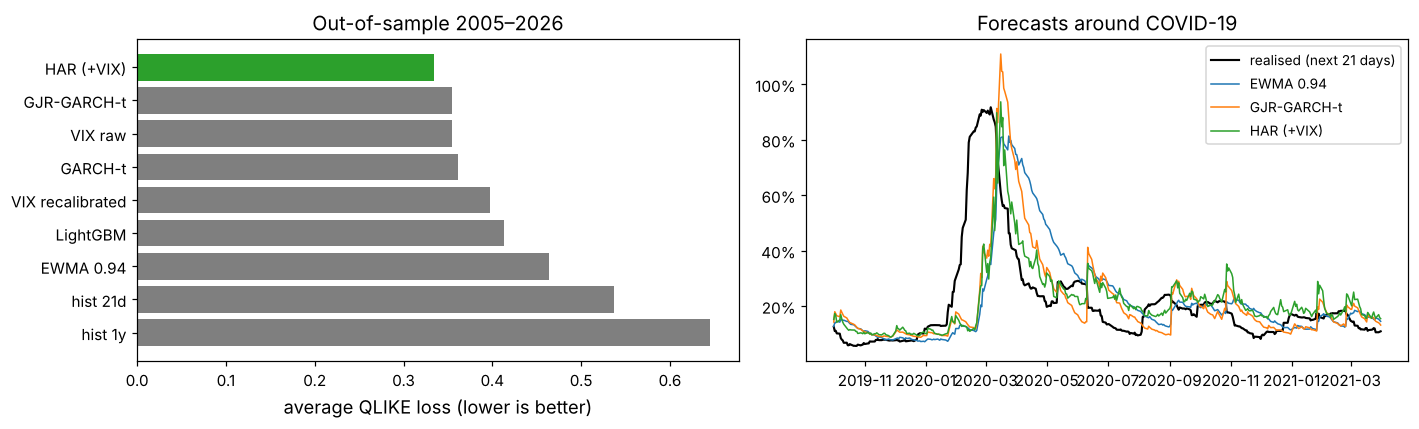

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = scores["QLIKE"].sort_values(ascending=False)
ax[0].barh(order.index, order.values, color=["tab:green" if n == best else "tab:gray" for n in order.index])
ax[0].set_xlabel("average QLIKE loss (lower is better)"); ax[0].set_title("Out-of-sample 2005–2026")
w = ev.loc["2019-10":"2021-03"]
ax[1].plot(ann(w["target"] / H), "k", lw=1.4, label="realised (next 21 days)")
for name in ["EWMA 0.94", "GJR-GARCH-t", "HAR (+VIX)"]:
    ax[1].plot(ann(w[models[name]] / H), lw=1, label=name)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].legend(fontsize=9); ax[1].set_title("Forecasts around COVID-19")
save_fig("model_comparison"); plt.show()

![Figure 3-3. Left: average out-of-sample QLIKE loss of each model. Right: forecasts and realised volatility through the 2020 crash. Note that every forecast lags the realised path: the target is in the future.](images/model_comparison.png)

The ranking:

- The worst forecasts are those that ignore recent information: the one-year average (QLIKE 0.645) reacts far too slowly, and the 21-day average is not much better.
- EWMA (QLIKE 0.464) is a big step up from fixed windows but is clearly beaten by models with **mean reversion** (GARCH, GJR) and **several horizons** (HAR): after a crisis, EWMA keeps predicting crisis-level volatility, while those models know it will fade.
- The best model out of sample is **HAR (+VIX)** (QLIKE 0.334), and the GJR-GARCH, which builds in the leverage effect, ranks 2 of nine. LightGBM ranks 6: with the same inputs, a flexible learner did worse than models that encode the right structure, because trees cannot extrapolate beyond the volatility levels they have seen and the extremes are what matter.
- The raw VIX predicts an average volatility of 20.9% against 18.9% realised (biased upward by the risk premium), yet it ranks near the top: QLIKE penalises under-prediction more than over-prediction, so a forecast that is a little too high costs little. “Recalibrating” it with an ordinary least-squares regression removes the bias but makes its QLIKE *worse*. The lesson is general: **fit with the same loss you evaluate with.**

The Diebold–Mariano tests confirm that the improvements of GARCH, GJR-GARCH and HAR over EWMA are statistically reliable (p-values below 1%) even after accounting for the overlap of the targets; LightGBM's improvement is not (p ≈ 0.09).

:::trap
A volatility forecast scored with MSE on variance is judged almost entirely on a few crisis days, and a model can win by being “right” in October 2008 and mediocre everywhere else. Look at QLIKE, at MSE, and at the forecast plots, and be suspicious of a ranking that changes completely between them.
:::

## Use the forecasts: volatility targeting

The most common use of a volatility forecast in portfolio management: hold an exposure inversely proportional to the forecast, so that the portfolio's risk stays near a target. Here we target 15% annual volatility on SPY, cap leverage at 2, decide at the close and hold the next day, and pay 2 basis points per unit traded.

                          Sharpe (no rf)    vol  max DD  kurtosis  \
buy and hold                       0.641  0.189  -0.552    18.423   
target 15% (EWMA 0.94)             0.760  0.156  -0.351     5.852   
target 15% (GJR-GARCH-t)           0.758  0.141  -0.358     5.311   
target 15% (HAR (+VIX))            0.738  0.141  -0.392     4.536   

                          vol of 63d vol  
buy and hold                       0.099  
target 15% (EWMA 0.94)             0.023  
target 15% (GJR-GARCH-t)           0.020  
target 15% (HAR (+VIX))            0.023  


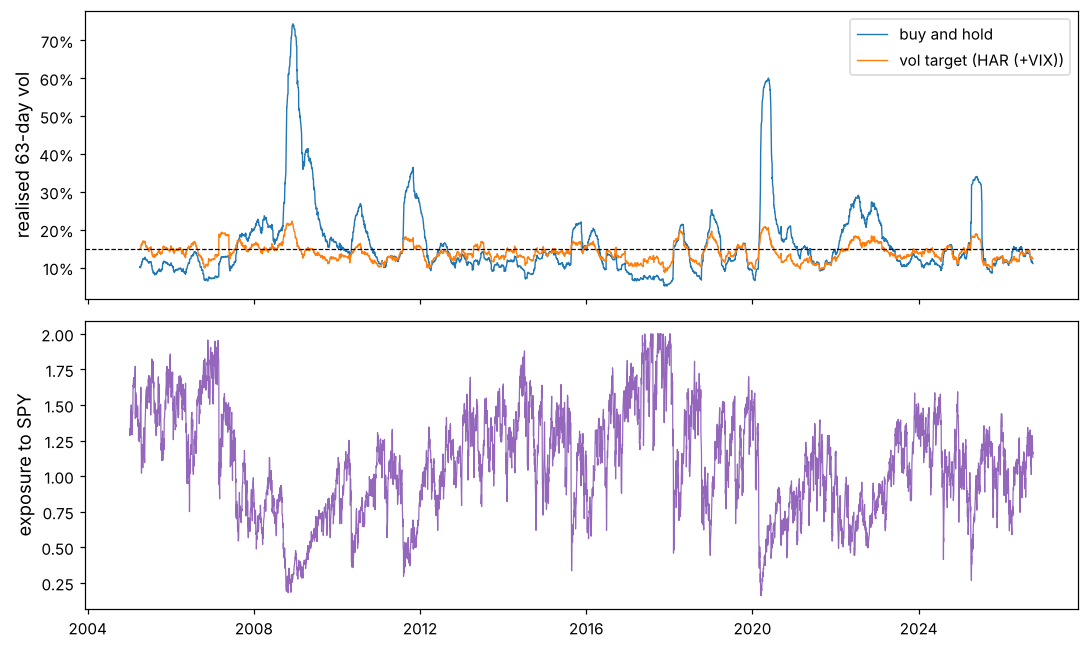

In [11]:
def vol_target(ret_next, fc_var_month, target=0.15, cap=2.0, cost_bps=2.0):
    vol_fc = np.sqrt(fc_var_month / H * 252)
    w = (target / vol_fc).clip(upper=cap)
    w_held = w.shift(1)                                        # decided at the close, held the next day
    turn = w_held.diff().abs()
    return (w_held * ret_next - turn * cost_bps / 1e4).dropna(), w_held.dropna()

simple = np.exp(df["r"]) - 1                                     # simple daily returns
tests = {"buy and hold": (simple.loc[ev.index[0]:], None)}
for name in ["EWMA 0.94", "GJR-GARCH-t", "HAR (+VIX)", best]:
    tests[f"target 15% ({name})"] = vol_target(simple, ev[models[name]].reindex(simple.index))
def sstats(x):
    x = x.dropna(); eq = (1 + x).cumprod()
    return pd.Series({"Sharpe (no rf)": x.mean() / x.std() * np.sqrt(252), "vol": x.std() * np.sqrt(252),
                      "max DD": (eq / eq.cummax() - 1).min(), "kurtosis": stats.kurtosis(x, fisher=False),
                      "vol of 63d vol": (x.rolling(63).std() * np.sqrt(252)).std()})
vt = pd.DataFrame({k: sstats(v[0].loc[ev.index[0]:]) for k, v in tests.items()}).T
print(vt.round(3))
R["bh_k"] = f"{vt.iloc[0]['kurtosis']:.1f}"; R["vt_k"] = f"{vt.loc[f'target 15% ({best})', 'kurtosis']:.1f}"
R["bh_vv"] = f"{vt.iloc[0]['vol of 63d vol']:.1%}"; R["vt_vv"] = f"{vt.loc[f'target 15% ({best})', 'vol of 63d vol']:.1%}"
R["bh_dd3"] = f"{vt.iloc[0]['max DD']:.0%}"; R["vt_dd3"] = f"{vt.loc[f'target 15% ({best})', 'max DD']:.0%}"
R["bh_s3"] = f"{vt.iloc[0]['Sharpe (no rf)']:.2f}"; R["vt_s3"] = f"{vt.loc[f'target 15% ({best})', 'Sharpe (no rf)']:.2f}"

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
bh_r = tests["buy and hold"][0]; vt_r, vt_w = tests[f"target 15% ({best})"]
ax[0].plot(bh_r.rolling(63).std() * np.sqrt(252), lw=0.9, label="buy and hold")
ax[0].plot(vt_r.rolling(63).std() * np.sqrt(252), lw=0.9, label=f"vol target ({best})")
ax[0].axhline(0.15, color="k", ls="--", lw=0.8); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[0].set_ylabel("realised 63-day vol"); ax[0].legend()
ax[1].plot(vt_w, lw=0.8, color="tab:purple"); ax[1].set_ylabel("exposure to SPY")
save_fig("vol_target"); plt.show()

![Figure 3-4. Top: realised volatility of buy and hold against the volatility-targeted portfolio (dashed: the 15% target). Bottom: the exposure to SPY, cut sharply in every crisis.](images/vol_target.png)

Volatility targeting does what it promises on risk: the realised volatility of the portfolio is much more stable (the standard deviation of its rolling volatility falls from 9.9% to 2.3%), the kurtosis of daily returns falls from 18.4 to 4.5, and the maximum drawdown changes from -55% to -39%. The Sharpe ratio moves from 0.64 to 0.74. Whether volatility targeting *raises* Sharpe ratios is debated (Moreira and Muir, 2017, found it does for many factors; later work found the gains fragile out of sample); its effect on risk is not debated.

:::quant
Why does scaling by volatility remove fat tails? Chapter 1 showed returns are close to “normal noise times a changing volatility”. Dividing by a good volatility forecast removes most of the changing part, leaving returns that are much closer to normal. The better the forecast, the more normal the result: the kurtosis of returns scaled by a forecast is itself a quick score of the forecast.
:::

## Present your solution

- **Deliverable:** a daily SPY 21-day volatility forecast from the **HAR (+VIX)** model, refitted every year, with EWMA as a fallback when inputs are missing.
- **Accuracy:** best out-of-sample QLIKE of nine models over 2005–2026; reacts within days to crises; never negative or explosive by construction (log targets).
- **Use:** volatility targeting cut the variability of risk and the tail of daily losses sharply.
- **Limits:** every model lags sudden jumps (they forecast tomorrow from today), and none predicts the *start* of a crisis. Overnight events (the 2020 lockdowns, the 2025 tariff announcements) hit before any forecast can react.

## Launch, monitor and maintain

Monitor the **ratio of realised to forecast variance** over rolling quarters: it should average about 1. Persistent values above 1 mean the model under-predicts (dangerous for risk limits); refit or fall back to EWMA. Log every forecast with its inputs; a sudden change in a forecast should always be explainable by an input.

## Try it out

::playground animations/garch_lab.html 790

Simulate a GARCH process with your own $\alpha$, $\beta$ and leverage term, see the volatility clusters it produces, the news impact curve, and how the multi-step forecast decays towards the long-run level.

## Exercises

:::exercise
1. Fit GARCH(1,1) with normal instead of Student-t innovations. Compare the parameters and the log-likelihood. Which parameter changes most, and why?
2. Score the forecasts with MSE instead of QLIKE. Does the ranking change? Which days drive the difference?
3. Add the HAR forecast and the recalibrated VIX together in an equal-weight **ensemble**. Does it beat both?
4. Plot the LightGBM feature importances (gain) averaged over the yearly refits. Which inputs matter most?
5. Run volatility targeting on the ten ETFs of Chapter 2, each scaled to 10% with its own EWMA forecast. How do the portfolio's drawdowns change?
:::

<details><summary>Solutions</summary>

In [12]:
# 1
pn = fit_garch(df["r"].to_numpy(), dist="normal")
print({k: round(v, 4) for k, v in pn.items() if k in ["alpha", "beta", "persistence", "loglik"]}, "vs t:", round(full["loglik"]))

# 2
mse_rank = {n: ((ev["target"] - ev[c]) ** 2).mean() for n, c in models.items()}
print(pd.Series(mse_rank).sort_values().index.tolist())

# 3
ens = 0.5 * ev["f_har"] + 0.5 * ev["f_vix_mz"]
print("ensemble QLIKE:", round(qlike(ev["target"], ens).mean(), 4), "| HAR", round(scores.loc["HAR (+VIX)", "QLIKE"], 4),
      "| VIX recal.", round(scores.loc["VIX recalibrated", "QLIKE"], 4))

# 4 (importances of the last refit)
print(pd.Series(model.booster_.feature_importance("gain"), index=Xg.columns).sort_values(ascending=False).round(0))

{'alpha': np.float64(0.1153), 'beta': np.float64(0.8674), 'loglik': np.float64(-50482.354), 'persistence': np.float64(0.9827)} vs t: -50255
['HAR (+VIX)', 'VIX raw', 'VIX recalibrated', 'GJR-GARCH-t', 'GARCH-t', 'EWMA 0.94', 'LightGBM', 'hist 21d', 'hist 1y']
ensemble QLIKE: 0.3525 | HAR 0.334 | VIX recal. 0.3974
vix2     47369.0
rv5      13715.0
rv63      7082.0
rv21      4366.0
ret21     3891.0
rv1       1228.0
ret5      1157.0
ret1       714.0
neg5       433.0
dtype: float64


</details>

## What's next

We now have forecasts of each asset's volatility. A portfolio also needs the **correlations** between assets, and estimating a covariance matrix from noisy data turns out to be harder, and more dangerous, than it looks. Chapter 4 builds portfolios out of sample and shows how shrinkage, risk parity and hierarchical clustering protect against estimation error.

In [13]:
# data for the playground: fitted parameters for its presets
Path("animations").mkdir(exist_ok=True)
pres = {"SPY GARCH-t": {k: float(full[k]) for k in ["omega", "alpha", "beta", "gamma"]},
        "SPY GJR-GARCH-t": {k: float(fullgjr[k]) for k in ["omega", "alpha", "beta", "gamma"]}}
Path("animations/data.js").write_text("window.GARCH_PRESETS = " + json.dumps(pres) + ";\n")
print(pres)

{'SPY GARCH-t': {'omega': 1.426122374681866e-06, 'alpha': 0.11626599115129889, 'beta': 0.8793121639221666, 'gamma': 0.0}, 'SPY GJR-GARCH-t': {'omega': 1.8235946212833525e-06, 'alpha': 3.8680785132444974e-16, 'beta': 0.8846585485840187, 'gamma': 0.19775493128823987}}
